# P6 baseline integration

Compare all six models on the same 3,451 matched training pairs. The archived A/B assignments and three discussion-grouped folds apply to every model. Each classifier fits feature scaling and logistic regression inside the training fold. The training runner reproduces the archived P6 out-of-fold probabilities. The published held-out data stay reserved.

| Model | Features |
| --- | --- |
| P6 | Archived full linguistic baseline |
| P6a | P6 with four ConvoKit indicators removed |
| P6b | P6a plus the 128-token Polite Guard score difference |
| P6c | P6a plus the 256-token Polite Guard score difference |
| P6d | P6a plus the 510-token Polite Guard score difference |
| P6e | P6 plus the 256-token Polite Guard score difference |

The ablation removes direct start, first-person plural, factuality, and direct question. P6a keeps word count, content-word frequency, reply delay, external links, net sentiment, and OP–reply semantic similarity.

[Training runner](train_baseline_integration.py) · [Point comparison](compare_baseline_integration.py)

In [1]:
from pathlib import Path
import json

import pandas as pd

project = next(
    path / "project" for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file() and (path / "team-setup").is_dir()
)
run_id = "20261124T060814527201Z"
run = project / "data/processed/linguistic-features/paired-models/p6_politeness_baseline_integration" / run_id
manifest = json.loads((run / "results.json").read_text())
assert manifest["split"] == "train" and manifest["p6_oof_reproduced"]
analysis = run / "analysis"
performance = pd.read_csv(analysis / "model_performance.csv").set_index("model")
table = performance.rename(columns={"Pairwise accuracy": "Pairwise accuracy (%)"})
table["Pairwise accuracy (%)"] *= 100
print(f"{manifest['pairs']:,} training pairs across {manifest['discussions']:,} discussions and {manifest['folds']} folds")
print(table.round(5).to_string())


3,451 training pairs across 2,507 discussions and 3 folds
       ROC-AUC  Pairwise accuracy (%)  Log loss  Correct pairs
model                                                         
P6     0.74681               68.00927   0.59657           2347
P6a    0.74901               68.12518   0.59548           2351
P6b    0.74824               68.44393   0.59560           2362
P6c    0.74829               68.53086   0.59576           2365
P6d    0.74818               68.58881   0.59569           2367
P6e    0.74614               67.80643   0.59684           2340


## Incremental performance

Each change is the model minus the indicated reference on the same pooled out-of-fold predictions. Positive changes favor the model for ROC-AUC and accuracy. Lower log loss is better. Accuracy differences are in percentage points.

In [2]:
incremental = pd.read_csv(analysis / "incremental_performance.csv")
incremental["Pairwise accuracy"] *= 100
incremental = incremental.rename(columns={
    "ROC-AUC": "Δ ROC-AUC", "Pairwise accuracy": "Δ accuracy (pp)",
    "Log loss": "Δ log loss", "Correct pairs": "Δ correct pairs",
})
print(incremental.set_index(["reference", "model"]).round(5).to_string())


                 Δ ROC-AUC  Δ accuracy (pp)  Δ log loss  Δ correct pairs
reference model                                                         
P6        P6a      0.00220          0.11591    -0.00109                4
          P6b      0.00143          0.43466    -0.00097               15
          P6c      0.00148          0.52159    -0.00081               18
          P6d      0.00137          0.57954    -0.00088               20
          P6e     -0.00067         -0.20284     0.00027               -7
P6a       P6      -0.00220         -0.11591     0.00109               -4
          P6b     -0.00077          0.31875     0.00012               11
          P6c     -0.00072          0.40568     0.00028               14
          P6d     -0.00083          0.46363     0.00021               16
          P6e     -0.00287         -0.31875     0.00136              -11


## What the point estimates show

- **P6a led on ROC-AUC and log loss.** Removing the four ConvoKit indicators raised ROC-AUC from 0.74681 to 0.74901, lowered log loss from 0.59657 to 0.59548, and produced four additional correct picks.
- **The three Polite Guard extensions of P6a made more correct picks.** They gained 11–16 correct picks, or 0.32–0.46 percentage points, over P6a. P6d had the highest accuracy at 68.59%. All three had slightly lower ROC-AUC and slightly higher log loss than P6a.
- **Adding the 256-token score to full P6 yielded slightly worse point estimates.** P6e lost seven correct picks, ROC-AUC fell by 0.00067, and log loss rose by 0.00027.

The models' rankings depend on the metric. The paired bootstrap will quantify uncertainty in these observed differences.

## Paired bootstrap intervals

Resample 2,507 original-poster discussions with replacement 1,000 times. Each draw includes all pairs belonging to every sampled discussion and uses the same discussion weights for every model. Compute the model-minus-reference difference within each draw and report its 2.5th and 97.5th percentiles. The intervals quantify variation across discussions with the fitted out-of-fold predictions held fixed. The intervals are pointwise across metrics and comparisons.

[Bootstrap runner](bootstrap_baseline_integration.py)

In [3]:
bootstrap = pd.read_csv(analysis / "bootstrap_intervals.csv")
for reference in ("P6", "P6a"):
    rows = bootstrap.loc[bootstrap["reference"].eq(reference)].copy()
    fields = ["change", "ci_low", "ci_high"]
    accuracy = rows["metric"].eq("Pairwise accuracy")
    rows.loc[accuracy, fields] *= 100
    rows.loc[accuracy, "metric"] = "Accuracy (pp)"
    print(f"Against {reference}")
    print(rows.drop(columns="reference").round(5).to_string(index=False))
    print()


Against P6
model        metric   change   ci_low  ci_high
  P6a       ROC-AUC  0.00220  0.00020  0.00434
  P6a Accuracy (pp)  0.11591 -0.46902  0.69441
  P6a      Log loss -0.00109 -0.00275  0.00042
  P6b       ROC-AUC  0.00143 -0.00151  0.00438
  P6b Accuracy (pp)  0.43466 -0.26543  1.13688
  P6b      Log loss -0.00097 -0.00314  0.00119
  P6c       ROC-AUC  0.00148 -0.00100  0.00396
  P6c Accuracy (pp)  0.52159 -0.08681  1.14522
  P6c      Log loss -0.00081 -0.00272  0.00098
  P6d       ROC-AUC  0.00137 -0.00125  0.00401
  P6d Accuracy (pp)  0.57954 -0.05855  1.25557
  P6d      Log loss -0.00088 -0.00283  0.00099
  P6e       ROC-AUC -0.00067 -0.00208  0.00079
  P6e Accuracy (pp) -0.20284 -0.58464  0.17332
  P6e      Log loss  0.00027 -0.00077  0.00129

Against P6a
model        metric   change   ci_low  ci_high
   P6       ROC-AUC -0.00220 -0.00434 -0.00020
   P6 Accuracy (pp) -0.11591 -0.69441  0.46902
   P6      Log loss  0.00109 -0.00042  0.00275
  P6b       ROC-AUC -0.00077 -0.0028

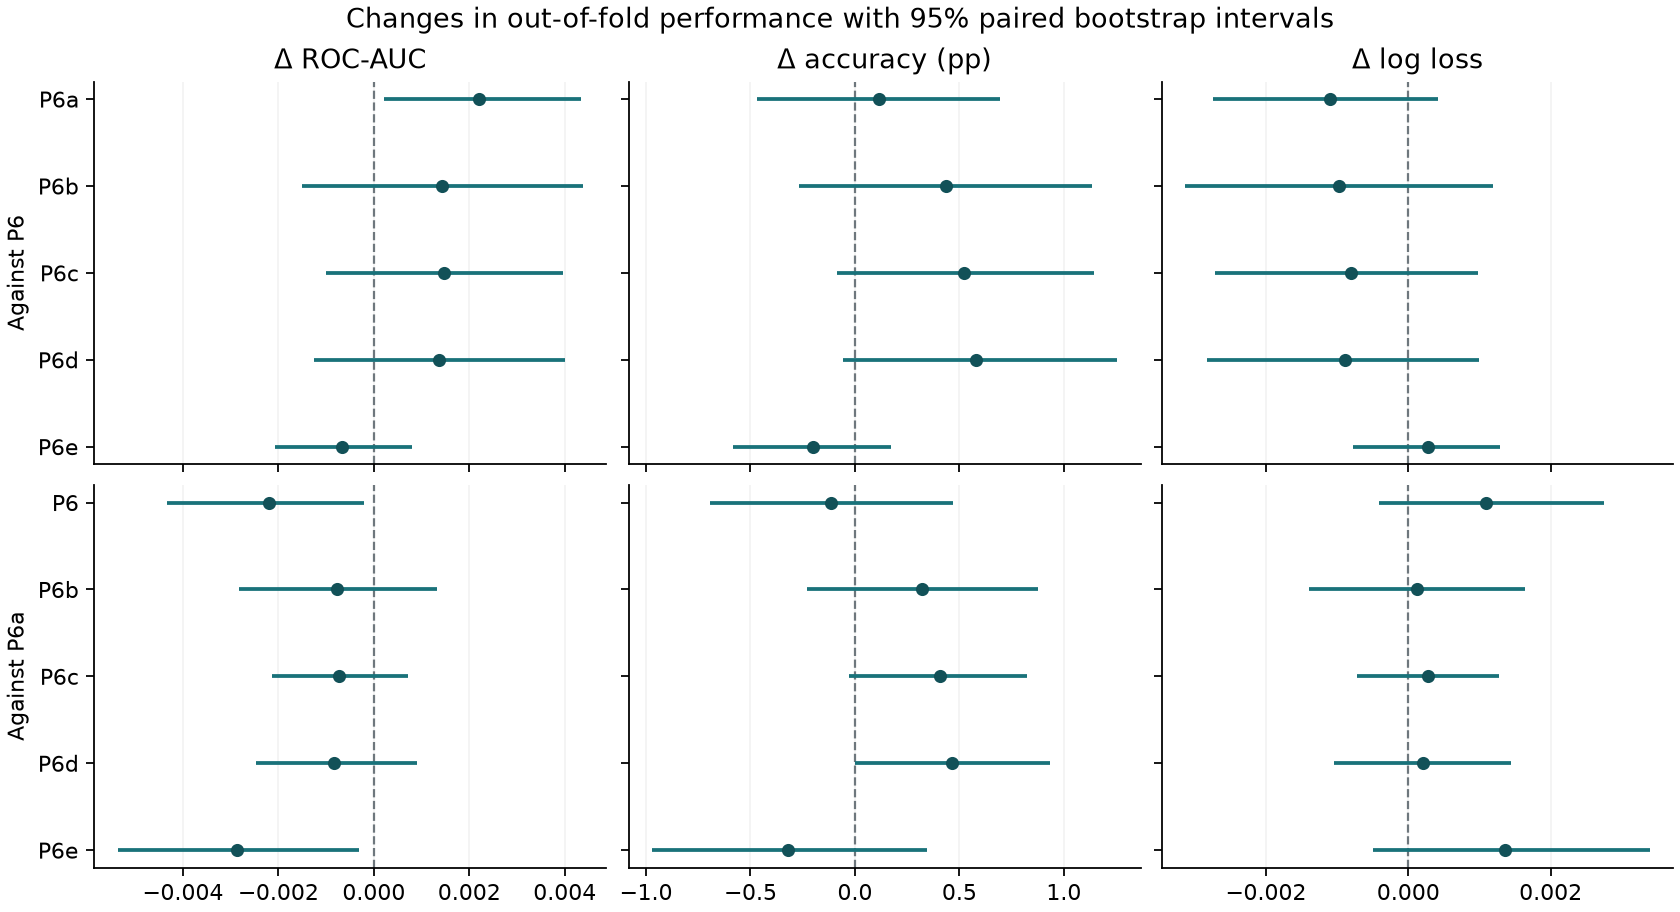

In [4]:
from IPython.display import Image, display

display(Image(filename=str(analysis / "incremental_confidence_intervals.png"),
              alt="Paired 95% intervals for changes in ROC-AUC, accuracy, and log loss against P6 and P6a"))


### What the intervals show

- **Removing the four ConvoKit indicators improved ROC-AUC by 0.00220** relative to P6 (95% CI 0.00020 to 0.00434). The accuracy and log-loss intervals included zero.
- **Adding Polite Guard to P6a showed no clear gain across the metrics.** The strongest accuracy estimate was P6d, with a gain of 0.46 percentage points (95% CI 0.00 to 0.93 points). All three ROC-AUC and log-loss intervals included zero.
- **P6e had lower ROC-AUC than P6a** by 0.00287 (95% CI −0.00537 to −0.00032). That comparison combines restoring the ConvoKit indicators and adding the 256-token score. In the direct P6e versus P6 comparison, every metric interval included zero.

These estimates come from grouped training folds. The published held-out split remains reserved.

## Standardized coefficients

For interpretation, refit each model on all 3,451 training pairs. Each feature is scaled by its full-training standard deviation, which is shared across models that use that feature. A coefficient is the change in log odds of an A win for a one-standard-deviation increase in the A-minus-B feature difference, with the other included features held fixed. For Polite Guard, a positive coefficient favors the reply with the higher estimated politeness score.

The 95% intervals use 1,000 resamples of whole discussions. Each draw refits the penalized model with the feature scales held fixed. These are full-training association estimates. The preceding out-of-fold comparisons measure predictive gains. The coefficient CSV includes every feature in all six specifications.

[Coefficient runner](summarize_baseline_coefficients.py)

In [5]:
coefficients = pd.read_csv(analysis / "standardized_coefficients.csv")
politeness_coefficients = pd.read_csv(analysis / "contextual_politeness_coefficients.csv")
fields = ["model", "content_limit", "coefficient", "ci_low", "ci_high", "informative_pairs"]
print(politeness_coefficients[fields].round(5).to_string(index=False))


model  content_limit  coefficient   ci_low  ci_high  informative_pairs
  P6b            128      0.09701  0.01648  0.17483               3450
  P6c            256      0.05731 -0.02255  0.13837               3450
  P6d            510      0.07259 -0.01468  0.15956               3450
  P6e            256      0.05823 -0.02279  0.13895               3450


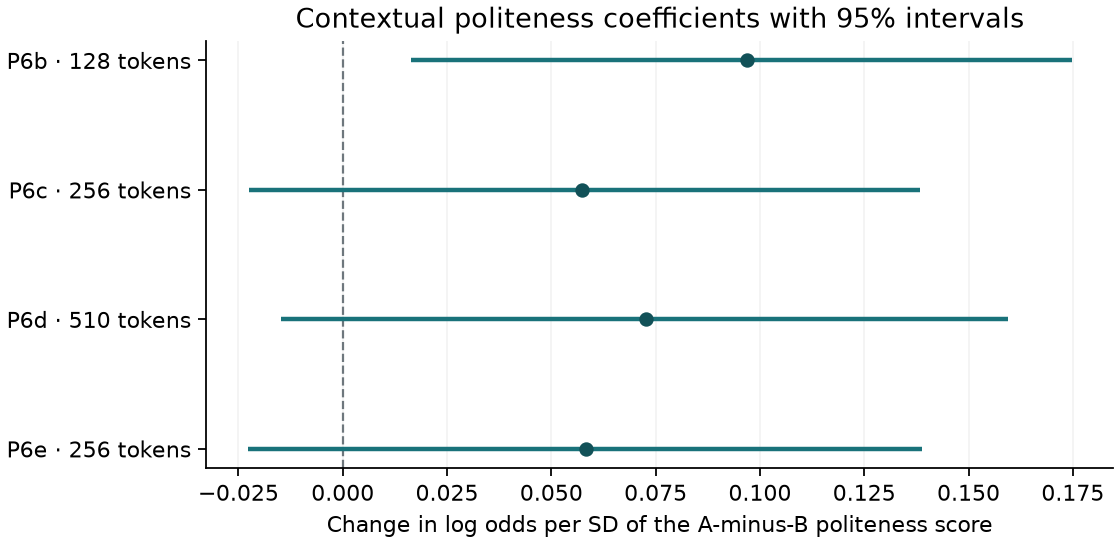

In [6]:
display(Image(filename=str(analysis / "contextual_politeness_coefficients.png"),
              alt="Standardized Polite Guard coefficients and 95% intervals for models P6b through P6e"))


### What the coefficients show

The 128-token score had the clearest positive association in its model (P6b, 0.097 log-odds units per standard deviation, 95% CI 0.016 to 0.175). The 256- and 510-token estimates were also positive, with intervals that included zero. The 256-token weight was similar with and without the four ConvoKit indicators (0.058 in P6e and 0.057 in P6c).

The coefficient results describe adjusted associations in training. The out-of-fold comparisons still show little evidence of an overall predictive gain from adding Polite Guard.